In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rootutils
import seaborn as sns
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

In [2]:
rootutils.setup_root(".", indicator=".project-root", pythonpath=True, cwd=True)
root = rootutils.find_root(search_from=".", indicator=".project-root")

In [3]:
# DETECTION
default = root / "output" / "five-runs"
baseline_configuration = "temporal=false-retriever=false-summarizer=false"
best_configuration_detection = "temporal=true-retriever=ddore14-sentence-roosebert-search=hybrid-rerank=cross-encoder-ms-marco-minilm-l-6-v2-query=relations_labeled-summarizer=false"
best_configuration_classification = "temporal=false-retriever=ddore14-sentence-roosebert-search=hybrid-rerank=cross-encoder-ms-marco-minilm-l-6-v2-query=relations_labeled-summarizer=false"


def predict_file(base):
    return next(base.glob("*/predict_results.txt"))


baseline_detection_best_model = "RooseBERT-scr-cased"
best_rag_detection_best_model = "ModernBERT-base"
BASIC_PATH_DETECTION = predict_file(
    default / "elecdeb60to20-detection" / baseline_configuration / baseline_detection_best_model / "seed_14")
BEST_RAG_PATH_DETECTION = predict_file(
    default / "elecdeb60to20-detection" / best_configuration_detection / best_rag_detection_best_model / "seed_14")

# CLASSIFICATION
baseline_classification_best_model = "RooseBERT-cont-cased"
best_rag_classification_best_model = "ModernBERT-base"
BASIC_PATH_CLASSIFICATION = predict_file(
    default / "elecdeb60to20-classification" / baseline_configuration / baseline_classification_best_model / "seed_14")
BEST_RAG_PATH_CLASSIFICATION = predict_file(
    default / "elecdeb60to20-classification" / best_configuration_classification / best_rag_classification_best_model / "seed_14")

In [4]:
def read_predictions(path: str):
    predictions = []
    with open(path) as f:
        for row in f.readlines()[1:]:
            _, prediction, gold = row.split("\t")
            predictions.append(
                {
                    'prediction': prediction.strip(),
                    'gold': gold.strip()
                }
            )
    return pd.DataFrame(predictions)

In [5]:
def error_analysis(path: str, title: str, filename: str):
    preds = read_predictions(path)
    print(preds.head())

    print(f"=================== Classification Report {title} ===================")
    print(classification_report(preds['gold'].tolist(), preds['prediction'].tolist()))

    # same ordering sklearn uses by default: sorted union of gold and predicted
    labels = sorted(set(preds['gold']) | set(preds['prediction']))
    n = len(labels)
    # shrink fonts / grow figure as the number of classes goes up
    annot_size = max(9, int(40 / n))
    tick_size = max(12, int(40 / n))

    cf_matrix = confusion_matrix(preds['gold'].tolist(), preds['prediction'].tolist(), labels=labels)
    plt.figure(figsize=(max(8.0, 1.7 * n), max(6.0, 1.5 * n)))
    sns.heatmap(cf_matrix / np.sum(cf_matrix),
                annot=True, fmt='.2%', cmap='Blues', annot_kws={"size": annot_size},
                xticklabels=labels, yticklabels=labels, square=True)
    plt.title(title, weight='bold', fontsize=24)
    plt.xlabel("Predicted", weight='bold', fontsize=22)
    plt.ylabel("Gold", weight='bold', fontsize=22)
    plt.xticks(size=tick_size)
    plt.yticks(size=tick_size, rotation=0)
    plt.tight_layout()
    plt.savefig(root / f"misc/figures/{filename}.pdf", dpi=1200, bbox_inches='tight')
    plt.show()


  prediction       gold
0    Fallacy    Fallacy
1    Fallacy    Fallacy
2    Fallacy  NoFallacy
3  NoFallacy    Fallacy
4    Fallacy    Fallacy
=================== Classification Report RooseBERT-scr-cased 
 Baseline ===================
              precision    recall  f1-score   support

     Fallacy       0.74      0.85      0.79       163
   NoFallacy       0.82      0.70      0.76       164

    accuracy                           0.77       327
   macro avg       0.78      0.77      0.77       327
weighted avg       0.78      0.77      0.77       327



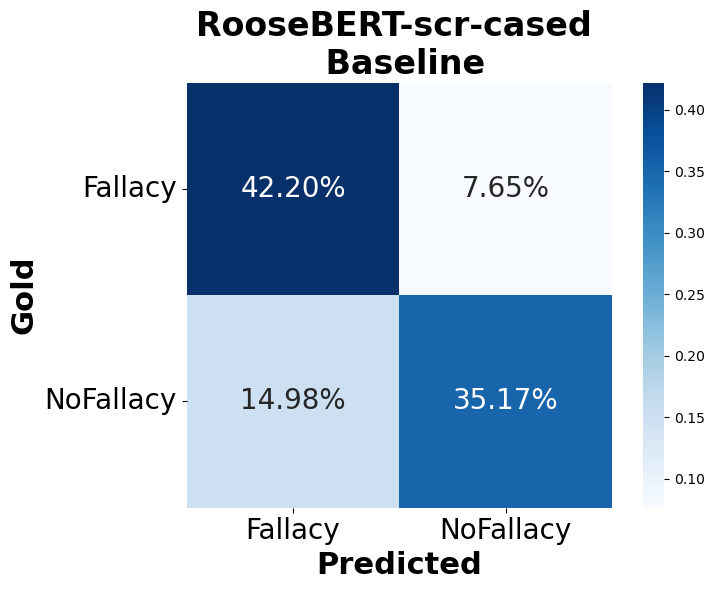

In [6]:
error_analysis(path=BASIC_PATH_DETECTION,
               title=f"{baseline_detection_best_model} \n Baseline",
               filename="cm_detection_basic")

  prediction       gold
0    Fallacy    Fallacy
1    Fallacy    Fallacy
2  NoFallacy  NoFallacy
3    Fallacy    Fallacy
4    Fallacy    Fallacy
=================== Classification Report ModernBERT-base 
 configuration with retrieval ===================
              precision    recall  f1-score   support

     Fallacy       0.84      0.93      0.88       163
   NoFallacy       0.92      0.82      0.87       164

    accuracy                           0.87       327
   macro avg       0.88      0.87      0.87       327
weighted avg       0.88      0.87      0.87       327



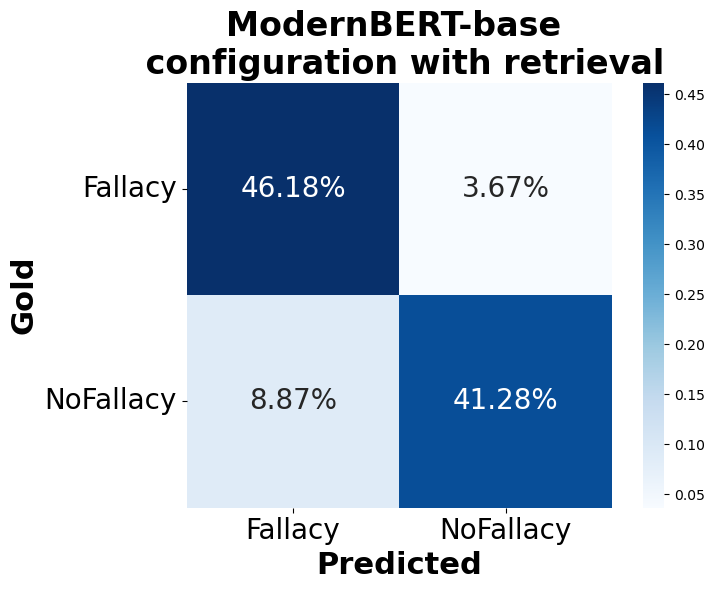

In [7]:
error_analysis(path=BEST_RAG_PATH_DETECTION,
               title=f"{best_rag_detection_best_model} \n configuration with retrieval",
               filename="cm_detection_rag")

        prediction             gold
0  AppealtoEmotion  AppealtoEmotion
1       FalseCause       FalseCause
2          Slogans          Slogans
3        AdHominem        AdHominem
4  AppealtoEmotion  AppealtoEmotion
=================== Classification Report RooseBERT-cont-cased 
 Baseline ===================
                   precision    recall  f1-score   support

        AdHominem       0.86      0.95      0.90        20
AppealtoAuthority       0.82      0.62      0.71        29
  AppealtoEmotion       0.80      0.84      0.82        92
       FalseCause       0.67      0.80      0.73        10
    Slipperyslope       0.40      0.50      0.44         8
          Slogans       1.00      0.25      0.40         4

         accuracy                           0.78       163
        macro avg       0.76      0.66      0.67       163
     weighted avg       0.79      0.78      0.78       163



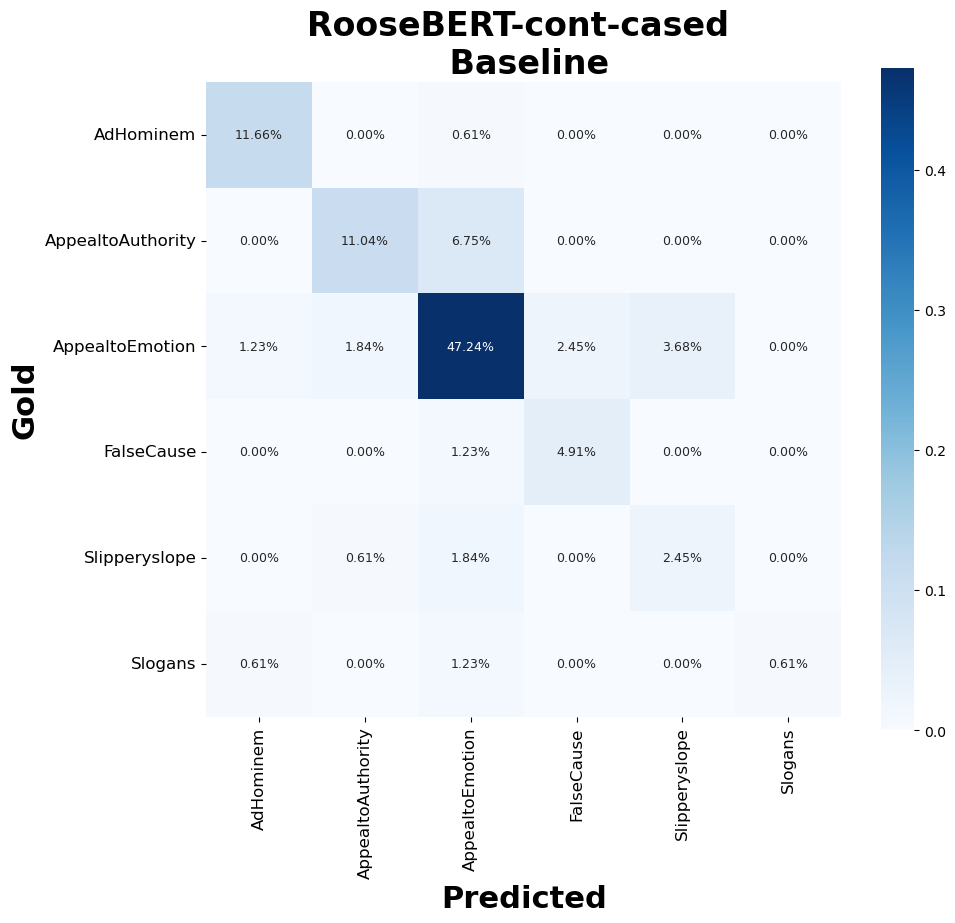

In [8]:
error_analysis(path=BASIC_PATH_CLASSIFICATION,
               title=f"{baseline_classification_best_model} \n Baseline",
               filename="cm_classification_basic")

          prediction             gold
0    AppealtoEmotion  AppealtoEmotion
1         FalseCause       FalseCause
2            Slogans          Slogans
3          AdHominem        AdHominem
4  AppealtoAuthority  AppealtoEmotion
=================== Classification Report ModernBERT-base 
 configuration with retrieval ===================
                   precision    recall  f1-score   support

        AdHominem       0.69      0.90      0.78        20
AppealtoAuthority       0.80      0.55      0.65        29
  AppealtoEmotion       0.79      0.86      0.82        92
       FalseCause       0.71      0.50      0.59        10
    Slipperyslope       0.57      0.50      0.53         8
          Slogans       1.00      0.75      0.86         4

         accuracy                           0.77       163
        macro avg       0.76      0.68      0.71       163
     weighted avg       0.77      0.77      0.76       163



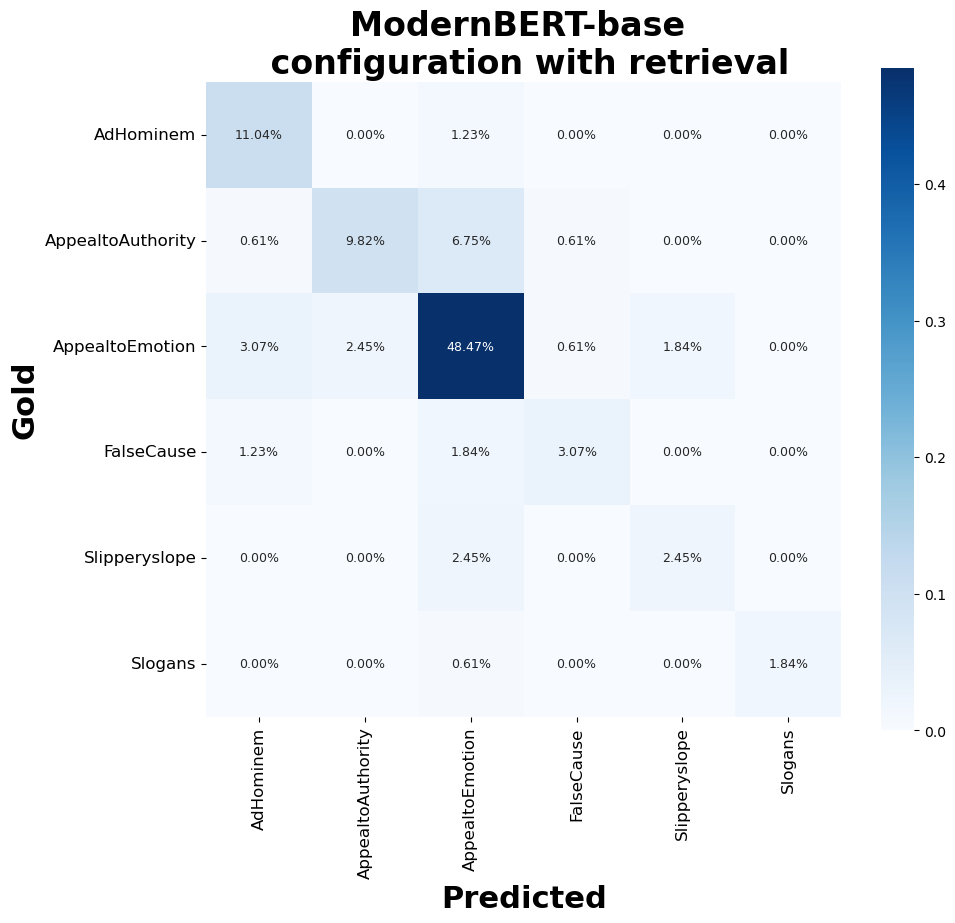

In [9]:
error_analysis(path=BEST_RAG_PATH_CLASSIFICATION,
               title=f"{best_rag_classification_best_model} \n configuration with retrieval",
               filename="cm_classification_rag")